# **FV Solver for the coupled Richards' and heat transport equation**
This notebook is used to simulate the coupled Richards and heat transport equation. It guides you through the simulation, which is set up in the Geom() class.
 

In [1]:
import sys
sys.path.append('../')
sys.path.append('../../')

import jax.numpy as jnp
from utils.geometry import Geom
from utils import plotting_utils
import utils.parameter_interpolation as inter
import pickle as pkl
import matplotlib.pyplot as plt

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


### State file and folder names

In [2]:
# Define parametrization
parametrization = "cap" # imp50, imp10, drying, drying_omega10, cap

# Path to forcing input
input_folder = "../../input/era5_land_data/Sweden/"
input_filename = "spinup_2308_2311.pkl"

# Path to predefined interpolation 
interp_folder = "../../input/interpolation/"
interp_filename = "interpolation_"+parametrization+".pkl"

# Path to output folder
save_folder = "../../output/spinup/"
save_filename = f"spinup_{parametrization}.pkl"

### Mesh Generation

In [3]:
dz = 0.025       # grid spacing [m]
dx = 0.025    # grid spacing [m]
ztot = 1       # height of the cross-sction [m]
xtot = 10   # length of the domain [m]
slope = -0.1   # slope of the domain [-]

geom = Geom(dx=dx, dz=dz, x_0=0, x_end=xtot, z_0=-ztot, z_end=0, slope=slope)  # geometry object

geom.create_grid()

===============   Creating grid   =============== 
DONE: created grid with  400 x 40 cells.


In [4]:
# Calculate and save sparsity pattern for mesh 
geom.set_sparsity_pattern()

===============   Calculating coupled sparsity pattern   =============== 


DONE: calculated coupled sparsity pattern with 316480 nonzero entries.


### Time Discretization

In [5]:
dt = 1     # time step [s]
t_end = 183*24*60*60 # end time [s]
maxdt = 6*60*60       # maximum time step [s]
save_t =24*60*60     # save output at time save_t [s]
t0 = 0
geom.time_discretization(dt, t0, t_end, maxdt, save_t) # time discretization


===============   Creating time discretization   =============== 
DONE: created time discretization.


### Define Soil Parameters

In [6]:
# Sandy soil parameters
soil_type = {1:{}, 2:{}}
soil = jnp.ones((geom.nz,geom.nx))  # soil type array
soil_type[1]["alpha"] = 14.5                        # van Genuchten alpha [1/m]
soil_type[1]["Ksat"] = 8.25e-5                      # saturated hydraulic conductivity [m/s]
soil_type[1]["N"] = 2.68                            # van Genuchten N [-]
soil_type[1]["Theta_r"] = 0.045                     # minimum volumetric water content [-]
soil_type[1]["Theta_s"] = 0.43                      # maximum volumetric water content [-]

# Loamy soil parameters
indices = jnp.where((geom.Z<=-.25+slope*geom.X) & (geom.Z>=-.5+slope*geom.X))
soil = soil.at[indices].set(2)
soil_type[2]["alpha"] = 1.6
soil_type[2]["Ksat"] = 6.94e-7
soil_type[2]["N"] = 1.37
soil_type[2]["Theta_r"] = 0.034
soil_type[2]["Theta_s"] = 0.46

### Interpolation of Hydraulic Parameters
- interpolate $k_{rel}$ w.r.t. $h_c, T$
- interpolate $\theta_l$ w.r.t. $h_c, T$

In [7]:
# discretize S -> hc
Se = jnp.geomspace(1e-7,1-1e-7,int(1e5)) # effective saturation [-]

#   discretize T
T = jnp.append(jnp.append(jnp.arange(-30,-1,1),jnp.arange(-1,0,1e-3)),jnp.array([0.01,5]))#,jnp.arange(0,10,10)) # K

# interpolate krel and theta_l for each soil type
soil_type = inter.interpolate_parameter(Se, T, soil_type, filename=interp_folder+interp_filename, parametrization="cap", method='monotonic', extrapolate=True)
del T,Se

# save interpolated soil type parameters
geom.set_soilType(soil, soil_type)

Loaded interpolated soil type from file:  ../../input/interpolation/interpolation_cap.pkl


### Top Boundary Condition

Text(0.5, 0, '$t$ $[d]$')

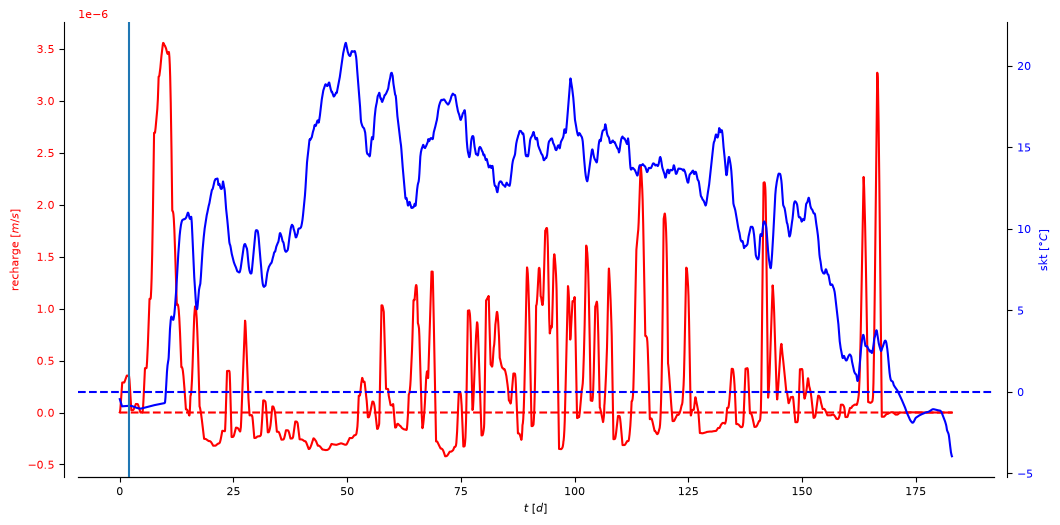

In [8]:
with open(input_folder + input_filename, "rb") as f:
    db = pkl.load(f)
    t_bc = jnp.array(db["time"])
    q_inf = jnp.convolve(jnp.array(db["recharge"]),jnp.ones(24)/24,mode="same")
    T_surface = jnp.convolve(jnp.array(db["tl1"]),jnp.ones(24)/24,mode="same")
geom.set_surface_bc(t_bc, q_inf, T_surface)

t_plot = jnp.arange(0, t_end,3600)
cm = 1/2.54
fig, ax = plt.subplots(figsize=(30*cm, 15*cm))
ax.plot(t_plot/24/60/60, geom.q_inf_interp(t_plot), label="recharge", color="red")
ax.set_ylabel("recharge $[m/s]$", color="red")
ax.tick_params(axis="y", labelcolor="red")
ax.plot(t_plot/24/60/60, 0*t_plot, "--",color="red")

ax_cp = ax.twinx()
ax_cp.set_ylabel("skt $[°C]$", color="blue")
ax_cp.plot(t_plot/24/60/60, geom.T_surface_interp(t_plot), label="skt", color="blue")
ax_cp.tick_params(axis="y", labelcolor="blue")
ax_cp.axhline(0, color="blue", linestyle="--")
ax_cp.axvline(2)

ax.spines["top"].set_visible(False)
ax_cp.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax_cp.spines["left"].set_visible(False)
ax.spines['left'].set_position(('outward', 10))
ax_cp.spines['right'].set_position(('outward', 10))

ax.set_xlabel("$t$ $[d]$")

### Define Initial Conditions

In [9]:
h_gw  = jnp.min(geom.Z)+.1 # Groundwater table at the right boundary [m]
htot= jnp.ones((geom.nz,geom.nx))*h_gw
h_c = jnp.ones((geom.nz,geom.nx))*geom.Z-htot
h_c = h_c.at[jnp.where(h_c<0)].set(0)
T_init = (5*jnp.ones((geom.nz,geom.nx)))  # initialcond temperature

### Plot Initial $\theta_l$ and $k_{rel}$

(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': 'Initial $\\theta_l$'}, xlabel='x [m]', ylabel='z [m]'>)

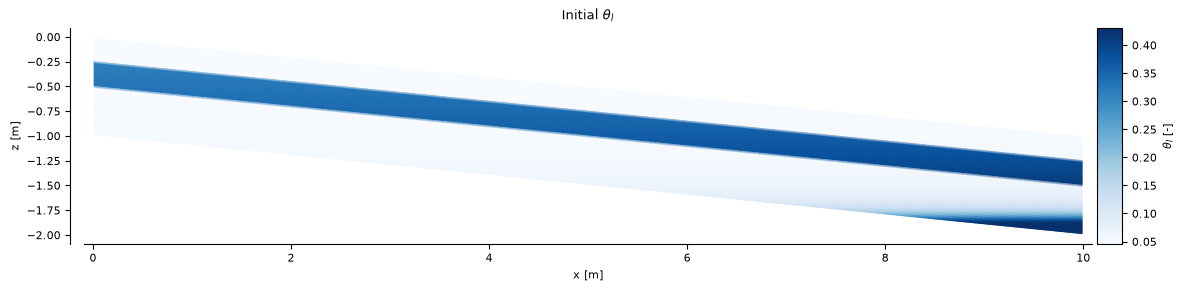

In [10]:
theta_l = jnp.where(geom.soil==1, geom.soil_type[1]["theta_l_interp"](h_c.flatten(), T_init.flatten()).reshape(h_c.shape), geom.soil_type[2]["theta_l_interp"](h_c.flatten(), T_init.flatten()).reshape(h_c.shape))
plotting_utils.plot_cellValues(geom.X,geom.Z, theta_l, colormap="Blues", title=r"Initial $\theta_l$", colorbar_label=r'$\theta_l$ [-]')

(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': 'Initial $k_{rel}$'}, xlabel='x [m]', ylabel='z [m]'>)

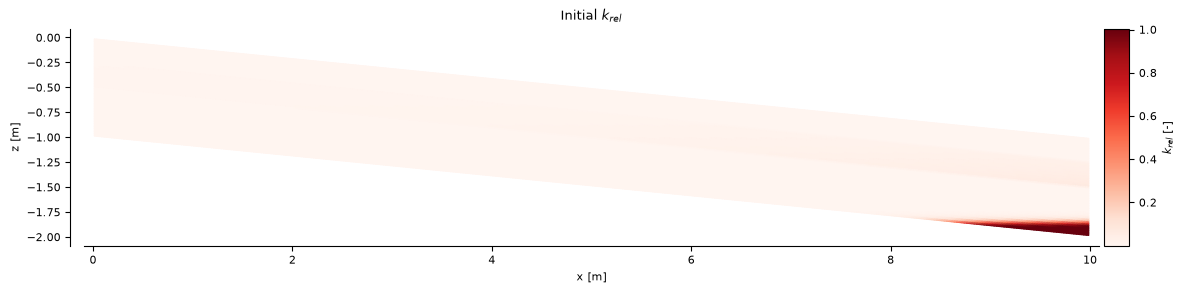

In [11]:
krel = jnp.where(geom.soil==1, geom.soil_type[1]["k_rel_interp"](h_c.flatten(), T_init.flatten()).reshape(h_c.shape), geom.soil_type[2]["k_rel_interp"](h_c.flatten(), T_init.flatten()).reshape(h_c.shape))
plotting_utils.plot_cellValues(geom.X,geom.Z, krel, colormap="Reds", title=r"Initial $k_{rel}$", colorbar_label=r'$k_{rel}$ [-]')

### Set Initial Condition

In [12]:
geom.set_initial_conditions(htot, h_c, theta_l, 0*theta_l, T_init)

===============   Setting initial conditions   =============== 
DONE: set initial conditions.


### Thermal Parameters

In [13]:
rho_l = 998
rho_i = 917
rho_s = 2650
rho_a = 1.1

c_s = 1923720 / rho_s
c_l = 4182000 / rho_l
c_i = 1895200 / rho_i
c_a = 1228.08 / rho_a

lambda_s = 2.9
lambda_l = 0.6
lambda_i = 2.14
lambda_a = 0.0262

H_f = 3.34e8 / rho_i
geom.set_thermal_params(rho_l, rho_i, rho_s, rho_a, c_s, c_l, c_i, c_a, lambda_l, lambda_i, lambda_s, lambda_a,H_f)

### Numerical Parameters

In [14]:
rtol_rich=1e-4      # accepted residual in Newton step
atol_rich=1e-4      # accepted absolute residual in Newton step
atol_T=1e2          # accepted absolute residual in Newton step
rtol_T=1e-2
maxiter=20          # maxmum number of iterations in Newton step
miniter=5           # minimum number of iterations in Newton step

geom.set_newton_params(atol_rich, rtol_rich, atol_T, rtol_T, maxiter, miniter)

===============   Setting Newton-Raphson parameters   =============== 
DONE: set Newton-Raphson parameters.


### Run simulation 

In [15]:
[h_total, h_c_total, theta_l_total,theta_i_total, T_total, q_runoff, qx_array,qz_array,qx_centered_array,qz_centered_array, time_array, iter_total, normres_total]=geom.simulate()

Starting simulation ...
Time 0.00 d, dt=1.00e+00, NR iterations=3, ||res||_inf=1.842e+02
Time 0.00 d, dt=1.00e+00, NR iterations=3, ||res||_inf=3.308e-01
Time 0.00 d, dt=1.00e+00, NR iterations=2, ||res||_inf=3.156e+01
Time 0.00 d, dt=1.20e+00, NR iterations=2, ||res||_inf=1.030e+01
Time 0.00 d, dt=1.20e+00, NR iterations=2, ||res||_inf=1.104e+01
Time 0.00 d, dt=1.20e+00, NR iterations=2, ||res||_inf=3.356e+00
Time 0.00 d, dt=1.44e+00, NR iterations=2, ||res||_inf=1.020e+00
Time 0.00 d, dt=1.44e+00, NR iterations=2, ||res||_inf=2.500e+00
Time 0.00 d, dt=1.44e+00, NR iterations=2, ||res||_inf=1.084e+00
Time 0.00 d, dt=1.73e+00, NR iterations=2, ||res||_inf=7.249e-01
Time 0.00 d, dt=1.73e+00, NR iterations=2, ||res||_inf=7.280e+01
Time 0.00 d, dt=1.73e+00, NR iterations=2, ||res||_inf=3.197e-01
Time 0.00 d, dt=2.07e+00, NR iterations=2, ||res||_inf=3.812e-01
Time 0.00 d, dt=2.07e+00, NR iterations=2, ||res||_inf=3.550e-01
Time 0.00 d, dt=2.07e+00, NR iterations=2, ||res||_inf=2.451e-01
T

/home/anne/anaconda3/envs/cryorich_AD/lib/python3.12/site-packages/jax/experimental/sparse/linalg.py:549: MatrixRankWarning: Matrix is exactly singular
  return (scipy.sparse.linalg.spsolve(A, b).astype(b.dtype),)


Max iterations reached with ||res_rich||=nan, ||res_T||=nan. Halving dt to 675.0
Max iterations reached with ||res_rich||=4.837e-05, ||res_T||=1.929e+04. Halving dt to 337.5
Time 10.30 d, dt=3.38e+02, NR iterations=14, ||res||_inf=2.319e+02
Time 10.31 d, dt=3.38e+02, NR iterations=16, ||res||_inf=1.052e+01
Time 10.31 d, dt=3.38e+02, NR iterations=3, ||res||_inf=2.787e+02
Time 10.31 d, dt=3.38e+02, NR iterations=5, ||res||_inf=8.042e+01
Time 10.32 d, dt=3.38e+02, NR iterations=6, ||res||_inf=4.564e+02
Time 10.32 d, dt=3.38e+02, NR iterations=4, ||res||_inf=8.555e+01
Time 10.33 d, dt=3.38e+02, NR iterations=4, ||res||_inf=1.111e+02
Time 10.33 d, dt=3.38e+02, NR iterations=5, ||res||_inf=1.445e+02
Time 10.33 d, dt=4.05e+02, NR iterations=3, ||res||_inf=1.557e+02
Time 10.34 d, dt=4.05e+02, NR iterations=3, ||res||_inf=1.518e+02
Time 10.34 d, dt=4.05e+02, NR iterations=3, ||res||_inf=2.963e+01
Time 10.35 d, dt=4.86e+02, NR iterations=3, ||res||_inf=1.736e+02
Time 10.35 d, dt=4.86e+02, NR it

### Plot final simulation output

(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': 't=183.0 days'}, xlabel='x [m]', ylabel='z [m]'>)

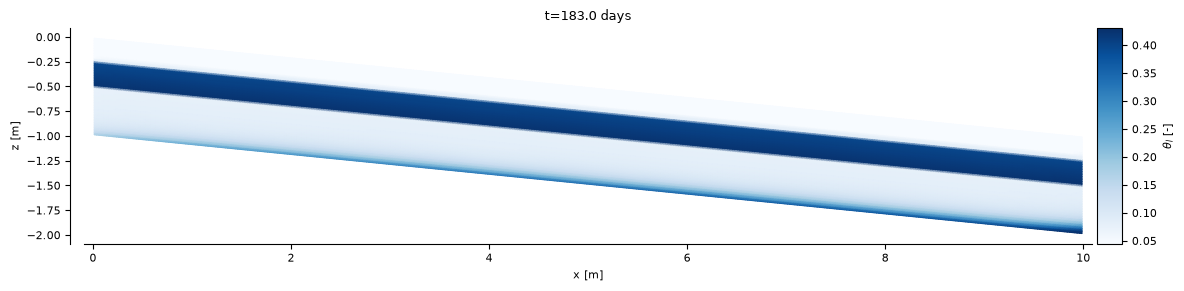

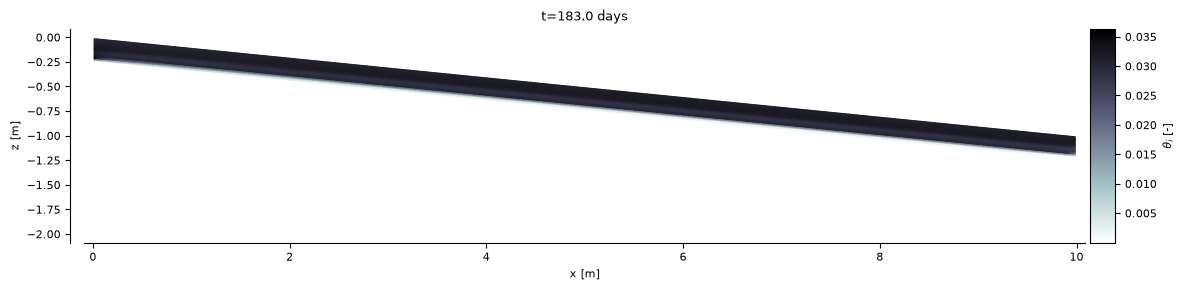

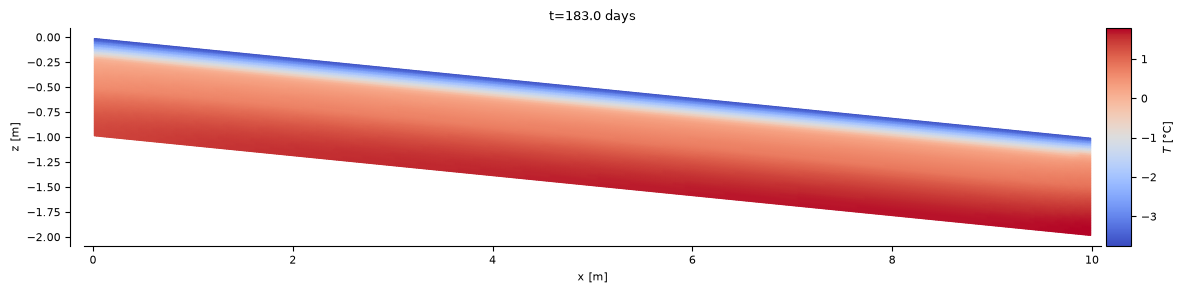

In [16]:
index = -1  # final time step

# plotting_utils.plot_lineProfile(geom, Se, krel, x_position=60, xlabel1=r"$S_e$ [m]", xlabel2=r"$k_{rl}$ [-]")

plotting_utils.plot_cellValues(geom.X,geom.Z, theta_l_total[index], colormap="Blues", title=f"t={jnp.round(time_array[index]/60/60/24)} days", colorbar_label=r'$\theta_l$ [-]')
plotting_utils.plot_cellValues(geom.X,geom.Z, theta_i_total[index], colormap="bone_r", title=f"t={jnp.round(time_array[index]/60/60/24)} days", colorbar_label=r'$\theta_i$ [-]')
plotting_utils.plot_cellValues(geom.X,geom.Z, T_total[index], colormap="coolwarm", title=f"t={jnp.round(time_array[index]/60/60/24)} days", colorbar_label=r'$T$ [°C]')

### Plot overview of runoff

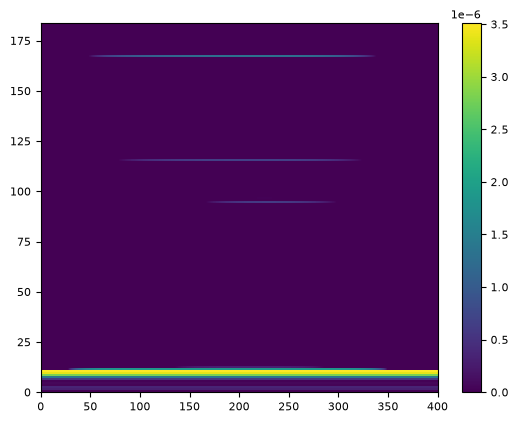

In [17]:
plt.pcolormesh(q_runoff)
plt.colorbar()

### Save simulation output to pickle file

In [18]:
db = {"X": geom.X, "Z":geom.Z,"X_plot":geom.X_plot, "Z_plot":geom.Z_plot, "q_runoff":q_runoff,
      "q_inf_interp":geom.q_inf_interp,"T_surface_interp": geom.T_surface_interp,
      "h_total": h_total, "h_c_total": h_c_total,"theta_l_total":theta_l_total, "theta_i_total":theta_i_total,"T_total": T_total, 
      "qx_array":qx_array,"qz_array":qz_array,"qx_centered_array":qx_centered_array,"qz_centered_array":qz_centered_array,
      "time_array": time_array, "iter_total": iter_total, "normres_total": normres_total}
with open(save_folder+save_filename, 'wb') as pickle_file:
    pkl.dump(db, pickle_file)